# Trabajo Práctico 1

El objetivo de este trabajo es resolver la ecuación de ondas en un cuadrado:

$$
\left\{
\begin{array}{ll}
u_{tt} = a\Delta u + f(x,y,t),
& (x,y)\in\Omega=[0,1]^2,\quad t\in[0,T], \\[6pt]
u(x,y,0)=g(x,y),
& (x,y)\in\Omega, \\[6pt]
u_t(x,y,0)=h(x,y),
& (x,y)\in\Omega, \\[6pt]
u(x,y,t)=0,
& (x,y)\in\partial\Omega.
\end{array}
\right.
$$

## Ejercicio 1

Implementar un programa que utilice la discretización:

$$
\frac{u_{i,j}^{n+1}-2u_{i,j}^{n}+u_{i,j}^{n-1}}{\Delta t^2}
=
a\cdot\frac{1}{2}
\left(
\frac{\delta_x^2 u^{n+1}}{\Delta x^2}
+
\frac{\delta_y^2 u^{n+1}}{\Delta y^2}
+
\frac{\delta_x^2 u^{n-1}}{\Delta x^2}
+
\frac{\delta_y^2 u^{n-1}}{\Delta y^2}
\right).
$$

Utilizar diferencias centradas para el dato inicial sobre $u_t$.

El programa debe recibir como parámetros los pasos espaciales
$\Delta x$, $\Delta y$, el paso temporal $\Delta t$, el tiempo final $T$,
el coeficiente $a$, el dato inicial $g$ y la fuente $f$.

El resultado debe ser un gráfico o animación que muestre la evolución
de la solución en el tiempo.

#Esquema implícito

Usamos el esquema

$$
\frac{
u_{i,j}^{m+1}-2u_{i,j}^{m}+u_{i,j}^{m-1}
}{
\Delta t^2
}
=
\frac{a}{2}
\left(
\frac{\delta_x^2u^{m+1}}{\Delta x^2}
+
\frac{\delta_y^2u^{m+1}}{\Delta y^2}
+
\frac{\delta_x^2u^{m-1}}{\Delta x^2}
+
\frac{\delta_y^2u^{m-1}}{\Delta y^2}
\right)
+
f(x_i,y_j,t_m).
$$

Es decir,

$$
\frac{u_{i,j}^{m+1}-2u_{i,j}^{m}+u_{i,j}^{m-1}}{\Delta t^2}
=
\frac{a}{2}
\left[
\frac{u_{i+1,j}^{m+1}-2u_{i,j}^{m+1}+u_{i-1,j}^{m+1}}{\Delta x^2}
+
\frac{u_{i,j+1}^{m+1}-2u_{i,j}^{m+1}+u_{i,j-1}^{m+1}}{\Delta y^2}
+
\frac{u_{i+1,j}^{m-1}-2u_{i,j}^{m-1}+u_{i-1,j}^{m-1}}{\Delta x^2}
+
\frac{u_{i,j+1}^{m-1}-2u_{i,j}^{m-1}+u_{i,j-1}^{m-1}}{\Delta y^2}
\right]
+
f(x_i,y_j,t_m).
$$

Multipliquemos miembro a miembro por $\Delta t^2$, y llamemos $r=\frac{a}{2}\Delta t^2$. Luego,

$$
u_{i,j}^{m+1}
-
r
\left[
\frac{
u_{i+1,j}^{m+1}
-2u_{i,j}^{m+1}
+u_{i-1,j}^{m+1}
}{
\Delta x^2
}
+
\frac{
u_{i,j+1}^{m+1}
-2u_{i,j}^{m+1}
+u_{i,j-1}^{m+1}
}{
\Delta y^2
}
\right]
$$

$$
=
2u_{i,j}^{m}
-u_{i,j}^{m-1}
+
r
\frac{
u_{i+1,j}^{m-1}
-2u_{i,j}^{m-1}
+u_{i-1,j}^{m-1}
}{
\Delta x^2
}
+
r
\frac{
u_{i,j+1}^{m-1}
-2u_{i,j}^{m-1}
+u_{i,j-1}^{m-1}
}{
\Delta y^2
}
+
f(x_i,y_j,t_m)\Delta t^2.
$$

Agrupemos en cada lado de la igualdad las variaciones en $i$ y en $j$:

$$
-\frac{r}{\Delta y^2}u_{i,j+1}^{m+1}
+
\left(
1+\frac{2r}{\Delta x^2}
+\frac{2r}{\Delta y^2}
\right)
u_{i,j}^{m+1}
-
\frac{r}{\Delta y^2}u_{i,j-1}^{m+1}
-
\frac{r}{\Delta x^2}u_{i+1,j}^{m+1}
-
\frac{r}{\Delta x^2}u_{i-1,j}^{m+1}
$$

$$
=
\frac{r}{\Delta y^2}u_{i,j+1}^{m-1}
+
\left(
-1-\frac{2r}{\Delta x^2}
-\frac{2r}{\Delta y^2}
\right)
u_{i,j}^{m-1}
-
\frac{r}{\Delta y^2}u_{i,j-1}^{m-1}
+
\frac{r}{\Delta x^2}u_{i+1,j}^{m-1}
+
\frac{r}{\Delta x^2}u_{i-1,j}^{m-1}
+
f(x_i,y_j,t_m)\Delta t^2.
$$

Definimos

$$
A_1=
\begin{bmatrix}
1+\dfrac{2r}{\Delta x^2}+\dfrac{2r}{\Delta y^2}
&
-\dfrac{r}{\Delta y^2}
&
&
0
\\[2mm]
-\dfrac{r}{\Delta y^2}
&
\ddots
&
\ddots
&
\\
&
\ddots
&
\ddots
&
-\dfrac{r}{\Delta y^2}
\\
0
&
&
-\dfrac{r}{\Delta y^2}
&
1+\dfrac{2r}{\Delta x^2}+\dfrac{2r}{\Delta y^2}
\end{bmatrix}
\in\mathbb{R}^{N_y\times N_y}.
$$

Además,

$$
A_2=
\begin{bmatrix}
-\dfrac{r}{\Delta x^2}
&
&
0
\\
&
\ddots
&
\\
0
&
&
-\dfrac{r}{\Delta x^2}
\end{bmatrix}.
$$

Por lo tanto,

$$
A=
\begin{bmatrix}
A_1&A_2&&0\\
A_2&A_1&A_2&\\
&\ddots&\ddots&\ddots\\
0&&A_2&A_1
\end{bmatrix}
\in
\mathbb{R}^{(N_xN_y)\times(N_xN_y)}.
$$

Definimos

$$
C_1=-A_1,
\qquad
C_2=-A_2,
$$

y

$$
C=
\begin{bmatrix}
C_1&C_2&&0\\
C_2&C_1&C_2&\\
&\ddots&\ddots&\ddots\\
0&&C_2&C_1
\end{bmatrix}
\in
\mathbb{R}^{(N_xN_y)\times(N_xN_y)}.
$$

## Condición inicial para la velocidad

Del enunciado usamos diferencias centradas:

$$
\frac{u_{i,j}^{1}-u_{i,j}^{-1}}{2\Delta t}
=
h(x_i,y_j).
$$

Entonces,

$$
u_{i,j}^{-1}
=
u_{i,j}^{1}
-
2\Delta t\,h(x_i,y_j).
$$

Además,

$$
u_{i,j}^{0}=g(x_i,y_j).
$$

## Forma vectorial

Definimos

$$
U^n=
\begin{bmatrix}
u_{11}^{n}\\
u_{12}^{n}\\
\vdots\\
u_{1N_y}^{n}\\
u_{21}^{n}\\
\vdots\\
u_{2N_y}^{n}\\
\vdots
\end{bmatrix}
\in\mathbb{R}^{N_xN_y}.
$$

También,

$$
F(x,y,t_n)
=
\left[
f(x_i,y_j,t_n)
\right]
\in\mathbb{R}^{N_xN_y},
$$

$$
G(x,y)
=
\left[
g(x_i,y_j)
\right]
\in\mathbb{R}^{N_xN_y},
$$

$$
H(x,y)
=
\left[
h(x_i,y_j)
\right]
\in\mathbb{R}^{N_xN_y}.
$$

Para el primer paso temporal,

$$
AU^1
=
2G(x,y)
+
\Delta t^2F(x,y,0)
+
CU^{-1}.
$$

Usando

$$
U^{-1}=U^1-2\Delta t\,H(x,y),
$$

queda

$$
AU^1
=
2G(x,y)
+
\Delta t^2F(x,y,0)
+
CU^1
-
2\Delta t\,CH(x,y).
$$

Por lo tanto,

$$
(A-C)U^1
=
2G(x,y)
+
\Delta t^2F(x,y,0)
-
2\Delta t\,CH(x,y).
$$

Para los pasos siguientes,

$$
AU^{n+1}
=
2U^n
+
\Delta t^2F(x,y,t_n)
+
CU^{n-1}.
$$

## Condiciones de contorno

$$
U_{0,j}^{n}
=
U_{N_x,i}^{n}
=
0,
$$

$$
U_{i,0}^{n}
=
U_{i,N_y}^{n}
=
0.
$$

In [1]:
using LinearAlgebra
using Plots
#Pkg.add("LinearAlgebra")

In [2]:
function tridiagonal_bloques(A_1, A_2, Nx)
    Ny = size(A_1, 1)
    A = zeros(Nx*Ny, Nx*Ny)
    for i in 1:Nx
        filas = (i-1)*Ny+1 : i*Ny
        A[filas, filas] = A_1                      # bloque diagonal
        if i > 1
            A[filas, filas .- Ny] = A_2             # bloque subdiagonal
        end
        if i < Nx
            A[filas, filas .+ Ny] = A_2             # bloque superdiagonal
        end
    end
    return A
end


tridiagonal_bloques (generic function with 1 method)

In [3]:
r_x2 = 0.2   # r/Δx^2
r_y2 = 0.3   # r/Δy^2
Ny = 4

diag_principal = (1 + 2*r_x2 + 2*r_y2) * ones(Ny)
diag_sec       = -r_y2 * ones(Ny-1)

A_1 = Tridiagonal(diag_sec, diag_principal, diag_sec)


4×4 Tridiagonal{Float64, Vector{Float64}}:
  2.0  -0.3    ⋅     ⋅ 
 -0.3   2.0  -0.3    ⋅ 
   ⋅   -0.3   2.0  -0.3
   ⋅     ⋅   -0.3   2.0

In [4]:
A_2 = Diagonal(-r_x2 * ones(Ny))

4×4 Diagonal{Float64, Vector{Float64}}:
 -0.2    ⋅     ⋅     ⋅ 
   ⋅   -0.2    ⋅     ⋅ 
   ⋅     ⋅   -0.2    ⋅ 
   ⋅     ⋅     ⋅   -0.2

In [5]:
A = tridiagonal_bloques(A_1, A_2, 6)

24×24 Matrix{Float64}:
  2.0  -0.3   0.0   0.0  -0.2   0.0  …   0.0   0.0   0.0   0.0   0.0   0.0
 -0.3   2.0  -0.3   0.0   0.0  -0.2      0.0   0.0   0.0   0.0   0.0   0.0
  0.0  -0.3   2.0  -0.3   0.0   0.0      0.0   0.0   0.0   0.0   0.0   0.0
  0.0   0.0  -0.3   2.0   0.0   0.0      0.0   0.0   0.0   0.0   0.0   0.0
 -0.2   0.0   0.0   0.0   2.0  -0.3      0.0   0.0   0.0   0.0   0.0   0.0
  0.0  -0.2   0.0   0.0  -0.3   2.0  …   0.0   0.0   0.0   0.0   0.0   0.0
  0.0   0.0  -0.2   0.0   0.0  -0.3      0.0   0.0   0.0   0.0   0.0   0.0
  0.0   0.0   0.0  -0.2   0.0   0.0      0.0   0.0   0.0   0.0   0.0   0.0
  0.0   0.0   0.0   0.0  -0.2   0.0      0.0   0.0   0.0   0.0   0.0   0.0
  0.0   0.0   0.0   0.0   0.0  -0.2      0.0   0.0   0.0   0.0   0.0   0.0
  ⋮                             ⋮    ⋱               ⋮                
  0.0   0.0   0.0   0.0   0.0   0.0  …   0.0  -0.2   0.0   0.0   0.0   0.0
  0.0   0.0   0.0   0.0   0.0   0.0      0.0   0.0  -0.2   0.0   0.0   0.0
  0.0 

In [10]:
#Discretizar una función:
function disc(f, Δx, Δy, Nx, Ny, t)
    f_disc = zeros(Nx, Ny)
    for i in 1:Nx
        for j in 1:Ny
            f_disc[i, j] = f(i * Δx, j * Δy, t)
        end
    end
    return f_disc
end

disc (generic function with 1 method)

In [6]:
function esquema_implicito(a, Δx, Δy, Δt, T, Nx, Ny, U_0, Ut_0, f)
    N_t = Int(round(T/Δt))
    t = 0:Δt:T
    r = a/2*Δt^2
    u_0 = zeros(Nx*Ny)
    # Inicializamos la condición inicial
    for i in 1:Nx
        for j in 1:Ny
            u_0[(i-1)*Ny + j] = U_0(i*Δx, j*Δy)
        end
    end
    ut_0 = zeros(Nx*Ny)
    # Inicializamos la condición inicial de la derivada
    for i in 1:Nx
        for j in 1:Ny
            ut_0[(i-1)*Ny + j] = Ut_0(i*Δx, j*Δy)
        end
    end
    u_1 = zeros(Nx*Ny)

    # Armamos matrices de iteración
    A_1 = Tridiagonal( (-r/Δy^2)*ones(Ny-1), (1+2*r/Δx^2 + 2*r/Δy^2)*ones(Ny), (-r/Δy^2)*ones(Ny-1) )
    A_2 = Diagonal(-r/Δx^2*ones(Ny))
    C_1 = -A_1
    C_2 = -A_2
    A = tridiagonal_bloques(A_1, A_2, Nx)
    C = tridiagonal_bloques(C_1, C_2, Nx)
    F_0 = vec(disc(f, Δx, Δy, Nx, Ny,0))
    u_1 = (A-C) \ (2*u_0 + Δt^2 * F_0 - 2 * Δt * C * ut_0)

    u_new = zeros(Nx*Ny)

    for i in 1:N_t
        F_i = vec(disc(f, Δx, Δy, Nx, Ny,i*Δt))
        u_new = A \ (2*u_1 + Δt^2 * F_i + C * u_0)
        u_0 = u_1
        u_1 = u_new
    end
    return u_new
end

esquema_implicito (generic function with 1 method)

In [8]:
function esquema_implicito_con_animacion(a, Δx, Δy, Δt, T, Nx, Ny, U_0, Ut_0, f)
    N_t = Int(round(T/Δt))
    t = 0:Δt:T
    r = a/2*Δt^2
    u_0 = zeros(Nx*Ny)
    # Inicializamos la condición inicial
    for i in 1:Nx
        for j in 1:Ny
            u_0[(i-1)*Ny + j] = U_0(i*Δx, j*Δy)
        end
    end
    ut_0 = zeros(Nx*Ny)
    # Inicializamos la condición inicial de la derivada
    for i in 1:Nx
        for j in 1:Ny
            ut_0[(i-1)*Ny + j] = Ut_0(i*Δx, j*Δy)
        end
    end
    u_1 = zeros(Nx*Ny)

    # Armamos matrices de iteración
    A_1 = Tridiagonal( (-r/Δy^2)*ones(Ny-1), (1+2*r/Δx^2 + 2*r/Δy^2)*ones(Ny), (-r/Δy^2)*ones(Ny-1) )
    A_2 = Diagonal(-r/Δx^2*ones(Ny))
    C_1 = -A_1
    C_2 = -A_2
    A = tridiagonal_bloques(A_1, A_2, Nx)
    C = tridiagonal_bloques(C_1, C_2, Nx)
    F_0 = vec(disc(f, Δx, Δy, Nx, Ny,0))
    u_1 = (A-C) \ (2*u_0 + Δt^2 * F_0 - 2 * Δt * C * ut_0)

    u_new = zeros(Nx*Ny)

    x = Δx:Δx:Nx*Δx
    y = Δy:Δy:Ny*Δy

    anim = @animate for t_step in Δt:Δt:T

        # 1. Convertimos el vector solución a matriz de (Ny x Nx)
        U_interior = reshape(u_1, Ny, Nx)

        # 2. Creamos una matriz con bordes fijos en 0 (de tamaño (Ny+2) x (Nx+2))
        U_plot = zeros(Ny + 2, Nx + 2)

        # Copiamos la solución en el interior (los bordes quedan automáticamente en 0)
        U_plot[2:Ny+1, 2:Nx+1] = U_interior

        # 3. Definimos los ejes extendidos para incluir los bordes
        x_ext = range(0, 1, length = Nx + 2)
        y_ext = range(0, 1, length = Ny + 2)

        # 4. Graficamos con surface
        surface(
            x_ext, y_ext, U_plot,
            title = "Solución en t = $(round(t_step, digits=3))",
            xlabel = "x",
            ylabel = "y",
            zlabel = "U",
            zlims = (-1.0, 1.0),
            camera = (45, 30),
            colorbar=false
        )

        # Calculamos F en el tiempo actual
        F = vec(disc(f, Δx, Δy, Nx, Ny, t_step))

        # Calculamos la siguiente solución
        u_new = A \ (2*u_1 + Δt^2 * F + C * u_0)

        # Actualizamos
        u_0 = u_1
        u_1 = u_new
    end
    return anim
end


esquema_implicito_con_animacion (generic function with 1 method)

┌ Info: Saved animation to c:\Users\dot-c\Documents\Licenciatura en Matematicas\4°\Análisis Numérico\TP1\animacion.gif
└ @ Plots C:\Users\dot-c\.julia\packages\Plots\GIume\src\animation.jl:156


Plots.AnimatedGif("c:\\Users\\dot-c\\Documents\\Licenciatura en Matematicas\\4°\\Análisis Numérico\\TP1\\animacion.gif")
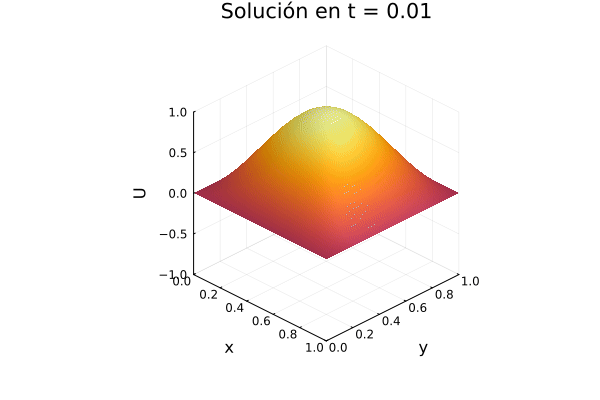

In [9]:
a = 1.0
Nx = 20
Ny = 20
Δx = 1.0 / (Nx+1)     # 0.05
Δy = 1.0 / (Ny+1)     # 0.05
Δt = 0.01         # Paso temporal
T = 2.0

U_0(x,y) = sin(π*x)*sin(π*y)
Ut_0(x,y) = 0.0
f(x,y,t) = 0.0

anim = esquema_implicito_con_animacion(a, Δx, Δy, Δt, T, Nx, Ny, U_0, Ut_0, f)

gif(anim, "animacion.gif", fps = 30)

# Esquema explícito

Usamos el esquema, con el laplaciano evaluado en el tiempo $m$:

$$
\frac{u_{i,j}^{m+1}-2u_{i,j}^{m}+u_{i,j}^{m-1}}{\Delta t^2}
=
a
\left(
\frac{\delta_x^2u^{m}}{\Delta x^2}
+
\frac{\delta_y^2u^{m}}{\Delta y^2}
\right)
+
f(x_i,y_j,t_m).
$$

Es decir,

$$
\frac{u_{i,j}^{m+1}-2u_{i,j}^{m}+u_{i,j}^{m-1}}{\Delta t^2}
=
a
\left[
\frac{u_{i+1,j}^{m}-2u_{i,j}^{m}+u_{i-1,j}^{m}}{\Delta x^2}
+
\frac{u_{i,j+1}^{m}-2u_{i,j}^{m}+u_{i,j-1}^{m}}{\Delta y^2}
\right]
+
f(x_i,y_j,t_m).
$$

Multipliquemos miembro a miembro por $\Delta t^2$, y llamemos $r=a\,\Delta t^2$ (en el código, `r_1`). Despejando $u_{i,j}^{m+1}$:

$$
u_{i,j}^{m+1}
=
2u_{i,j}^{m}
-u_{i,j}^{m-1}
+
r
\frac{u_{i+1,j}^{m}-2u_{i,j}^{m}+u_{i-1,j}^{m}}{\Delta x^2}
+
r
\frac{u_{i,j+1}^{m}-2u_{i,j}^{m}+u_{i,j-1}^{m}}{\Delta y^2}
+
f(x_i,y_j,t_m)\Delta t^2.
$$

Agrupemos las variaciones en $i$ y en $j$ (todo lo que está en el tiempo $m$):

$$
u_{i,j}^{m+1}
=
\frac{r}{\Delta y^2}u_{i,j+1}^{m}
+
\left(
2-\frac{2r}{\Delta x^2}
-\frac{2r}{\Delta y^2}
\right)
u_{i,j}^{m}
+
\frac{r}{\Delta y^2}u_{i,j-1}^{m}
+
\frac{r}{\Delta x^2}u_{i+1,j}^{m}
+
\frac{r}{\Delta x^2}u_{i-1,j}^{m}
-
u_{i,j}^{m-1}
+
f(x_i,y_j,t_m)\Delta t^2.
$$

Definimos

$$
A_1=
\begin{bmatrix}
2-\dfrac{2r}{\Delta x^2}-\dfrac{2r}{\Delta y^2}
&
\dfrac{r}{\Delta y^2}
&
&
0
\\[2mm]
\dfrac{r}{\Delta y^2}
&
\ddots
&
\ddots
&
\\
&
\ddots
&
\ddots
&
\dfrac{r}{\Delta y^2}
\\
0
&
&
\dfrac{r}{\Delta y^2}
&
2-\dfrac{2r}{\Delta x^2}-\dfrac{2r}{\Delta y^2}
\end{bmatrix}
\in\mathbb{R}^{N_y\times N_y}.
$$

Y

$$
A_2=
\begin{bmatrix}
\dfrac{r}{\Delta x^2}
&
&
0
\\
&
\ddots
&
\\
0
&
&
\dfrac{r}{\Delta x^2}
\end{bmatrix}
\in\mathbb{R}^{N_y\times N_y}.
$$

Por lo tanto,

$$
A=
\begin{bmatrix}
A_1&A_2&&0\\
A_2&A_1&A_2&\\
&\ddots&\ddots&\ddots\\
0&&A_2&A_1
\end{bmatrix}
\in
\mathbb{R}^{(N_xN_y)\times(N_xN_y)}.
$$

## Condición inicial para la velocidad

Del enunciado usamos diferencias centradas:

$$
\frac{u_{i,j}^{1}-u_{i,j}^{-1}}{2\Delta t}
=
h(x_i,y_j).
$$

Entonces,

$$
u_{i,j}^{-1}
=
u_{i,j}^{1}
-
2\Delta t\,h(x_i,y_j).
$$

Además,

$$
u_{i,j}^{0}=g(x_i,y_j).
$$

## Forma vectorial

Definimos

$$
U^n=
\begin{bmatrix}
u_{11}^{n}\\
u_{12}^{n}\\
\vdots\\
u_{1N_y}^{n}\\
u_{21}^{n}\\
\vdots\\
u_{2N_y}^{n}\\
\vdots
\end{bmatrix}
\in\mathbb{R}^{N_xN_y},
$$

También,

$$
F(x,y,t_n)=\left[f(x_i,y_j,t_n)\right]\in\mathbb{R}^{N_xN_y},
\quad
G(x,y)=\left[g(x_i,y_j)\right]\in\mathbb{R}^{N_xN_y},
\quad
H(x,y)=\left[h(x_i,y_j)\right]\in\mathbb{R}^{N_xN_y}.
$$

Para el primer paso temporal:

$$
U^1
=
AU^0
+
\Delta t^2F(x,y,0)
-
U^{-1}.
$$

Usando

$$
U^{-1}=U^1-2\Delta t\,H(x,y),
$$

queda

$$
U^1
=
AU^0
+
\Delta t^2F(x,y,0)
-
U^1
+
2\Delta t\,H(x,y),
$$

y pasando $U^1$ al lado izquierdo,

$$
2U^1
=
AU^0
+
\Delta t^2F(x,y,0)
+
2\Delta t\,H(x,y).
$$

Por lo tanto,
$$
U^1
=
\frac{1}{2}AG(x,y)
+
\frac{1}{2}\Delta t^2F(x,y,0)
+
\Delta t\,H(x,y).
$$

Pasos siguientes:

$$
U^{n+1}
=
AU^n
+
\Delta t^2F(x,y,t_n)
-
U^{n-1},
\qquad n\ge 1.
$$

##Condiciones de contorno:

$$
U_{0,j}^{n}
=
U_{N_x+1,j}^{n}
=
0,
\qquad
U_{i,0}^{n}
=
U_{i,N_y+1}^{n}
=
0.
$$


In [7]:
function esquema_explicito(a, Δx, Δy, Δt, T, Nx, Ny, U_0, Ut_0, f)
    N_t = Int(round(T/Δt))
    r_1 = a*Δt^2

    u_0 = zeros(Nx*Ny)
    # Condición inicial U^0 = G(x,y)
    for i in 1:Nx
        for j in 1:Ny
            u_0[(i-1)*Ny + j] = U_0(i*Δx, j*Δy)
        end
    end

    ut_0 = zeros(Nx*Ny)
    # Condición inicial de la derivada H(x,y)
    for i in 1:Nx
        for j in 1:Ny
            ut_0[(i-1)*Ny + j] = Ut_0(i*Δx, j*Δy)
        end
    end

    # Armamos matrices del esquema explícito
    A_1 = Tridiagonal( (r_1/Δy^2)*ones(Ny-1), (2 - 2*r_1/Δx^2 - 2*r_1/Δy^2)*ones(Ny), (r_1/Δy^2)*ones(Ny-1) )
    A_2 = Diagonal(r_1/Δx^2*ones(Ny))
    A = tridiagonal_bloques(A_1, A_2, Nx)

    # Primer paso: U^1 = (1/2) A U^0 + (1/2) Δt^2 F(x,y,0) + Δt H(x,y)
    F_0 = vec(disc(f, Δx, Δy, Nx, Ny, 0))
    u_1 = 0.5 * (A * u_0) + 0.5 * Δt^2 * F_0 + Δt * ut_0

    u_new = zeros(Nx*Ny)

    for m in 1:N_t
        F_m = vec(disc(f, Δx, Δy, Nx, Ny, m*Δt))
        u_new = A * u_1 + Δt^2 * F_m - u_0
        u_0 = u_1
        u_1 = u_new
    end
    return u_new
end

esquema_explicito (generic function with 1 method)

In [11]:
function esquema_explicito_con_animacion(a, Δx, Δy, Δt, T, Nx, Ny, U_0, Ut_0, f)
    N_t = Int(round(T/Δt))
    r_1 = a*Δt^2

    u_0 = zeros(Nx*Ny)
    # Inicializamos la condición inicial
    for i in 1:Nx
        for j in 1:Ny
            u_0[(i-1)*Ny + j] = U_0(i*Δx, j*Δy)
        end
    end
    ut_0 = zeros(Nx*Ny)
    # Inicializamos la condición inicial de la derivada
    for i in 1:Nx
        for j in 1:Ny
            ut_0[(i-1)*Ny + j] = Ut_0(i*Δx, j*Δy)
        end
    end

    # Armamos matrices del esquema explícito
    A_1 = Tridiagonal( (r_1/Δy^2)*ones(Ny-1), (2 - 2*r_1/Δx^2 - 2*r_1/Δy^2)*ones(Ny), (r_1/Δy^2)*ones(Ny-1) )
    A_2 = Diagonal(r_1/Δx^2*ones(Ny))
    A = tridiagonal_bloques(A_1, A_2, Nx)

    # Primer paso: U^1 = (1/2) A U^0 + (1/2) Δt^2 F(x,y,0) + Δt H(x,y)
    F_0 = vec(disc(f, Δx, Δy, Nx, Ny, 0))
    u_1 = 0.5 * (A * u_0) + 0.5 * Δt^2 * F_0 + Δt * ut_0

    u_new = zeros(Nx*Ny)

    x = Δx:Δx:Nx*Δx
    y = Δy:Δy:Ny*Δy

    anim_2 = @animate for t_step in Δt:Δt:T

        # 1. Convertimos el vector solución a matriz de (Ny x Nx)
        U_interior = reshape(u_1, Ny, Nx)

        # 2. Creamos una matriz con bordes fijos en 0 (de tamaño (Ny+2) x (Nx+2))
        U_plot = zeros(Ny + 2, Nx + 2)

        # Copiamos la solución en el interior (los bordes quedan automáticamente en 0)
        U_plot[2:Ny+1, 2:Nx+1] = U_interior

        # 3. Definimos los ejes extendidos para incluir los bordes
        x_ext = range(0, 1, length = Nx + 2)
        y_ext = range(0, 1, length = Ny + 2)

        # 4. Graficamos con surface
        surface(
            x_ext, y_ext, U_plot,
            title = "Solución en t = $(round(t_step, digits=3))",
            xlabel = "x",
            ylabel = "y",
            zlabel = "U",
            zlims = (-1.0, 1.0),
            camera = (45, 30),
            colorbar=false
        )

        # Calculamos F en el tiempo actual
        F = vec(disc(f, Δx, Δy, Nx, Ny, t_step))

        # Calculamos la siguiente solución (producto matricial directo, sin resolver sistema)
        u_new = A * u_1 + Δt^2 * F - u_0

        # Actualizamos
        u_0 = u_1
        u_1 = u_new
    end
    return anim_2
end

esquema_explicito_con_animacion (generic function with 1 method)

┌ Info: Saved animation to c:\Users\dot-c\Documents\Licenciatura en Matematicas\4°\Análisis Numérico\TP1\animacion_2.gif
└ @ Plots C:\Users\dot-c\.julia\packages\Plots\GIume\src\animation.jl:156


Plots.AnimatedGif("c:\\Users\\dot-c\\Documents\\Licenciatura en Matematicas\\4°\\Análisis Numérico\\TP1\\animacion_2.gif")
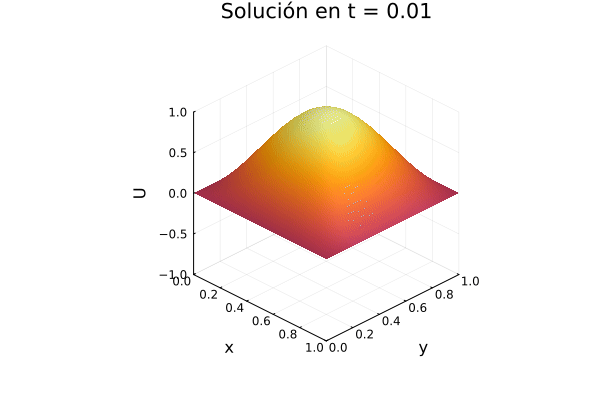

In [12]:
a = 1.0
Nx = 20
Ny = 20
Δx = 1.0 / (Nx+1)     # 0.05
Δy = 1.0 / (Ny+1)     # 0.05
Δt = 0.01         # Paso temporal
T = 2.0

U_0(x,y) = sin(π*x)*sin(π*y)
Ut_0(x,y) = 0.0
f(x,y,t) = 0.0

anim_2 = esquema_explicito_con_animacion(a, Δx, Δy, Δt, T, Nx, Ny, U_0, Ut_0, f)

gif(anim_2, "animacion_2.gif", fps = 30)

#Ejercicio 3

Estudie el orden de convergencia de ambos métodos. Considere la solución exacta

$$
u(x,y,t)=\left(\cos(\omega t)+\sin(\omega t)\right)\sin(\pi x)\sin(\pi y),
$$

con $\omega=\sqrt{2a\pi^2}$.

Realice una sucesión de refinamientos

$$
\Delta x=\Delta y,\qquad \Delta t
$$

(manteniendo $\Delta t$ proporcional a $\Delta x$) calculando el error en alguna norma discreta.

In [8]:
using Printf

function u_exacta(x, y, t)
  w = sqrt(2*pi^2)
  return (cos(w*t)+sin(w*t))*sin(pi*x)*sin(pi*y)
end

u_0(x,y) = u_exacta(x, y, 0)

function ut_0(x, y)
  w = sqrt(2*pi^2)
  return w*sin(pi*x)*sin(pi*y)
end

f(x, y, t) = 0

function error_convergencia(esquema; a, u_exacta, u_0, ut_0, f, r=0.4, T=0.1, Ns=[10,20,40,80,160])
    errores = Float64[]
    for N in Ns
        Δx = 1.0/(N+1)
        Δt = r*Δx
        U = esquema(a, Δx, Δx, Δt, T, N, N, u_0,ut_0, f)
        uex = vec(disc(u_exacta, Δx, Δx, N, N, T))
        push!(errores, maximum(abs.(U .- uex)))
    end
    return errores
end

function mostrar_error_convergencia(errores, r, T, Ns)
    @printf("%6s  %12s  %10s\n", "N", "err_inf", "orden α")
    for i in 1:length(Ns)
        if i == 1
            @printf("%6d  %12.3e  %10s\n", Ns[i], errores[i], "--")
        else
            α = log(errores[i-1]/errores[i]) / log(Ns[i]/Ns[i-1])
            @printf("%6d  %12.3e  %10.3f\n", Ns[i], errores[i], α)
        end
    end
end


mostrar_error_convergencia (generic function with 1 method)

## Orden de convergencia Esquema Implícito

In [11]:
Ns = [10, 20, 40, 50]
r  = 0.2
T  = 0.2

errores = error_convergencia(esquema_implicito; a=1, u_exacta=u_exacta, u_0=u_0, ut_0=ut_0, f=f, r=r, T=T, Ns=Ns)

mostrar_error_convergencia(errores, r, T, Ns)

     N       err_inf     orden α
    10     1.015e-02          --
    20     5.854e-03       0.794
    40     3.095e-03       0.919
    50     2.501e-03       0.956


## Orden de convergencia Esquema Explícito

In [13]:
Ns = [10, 20, 40, 50]
r  = 0.2
T  = 0.2

errores = error_convergencia(esquema_explicito; a=1, u_exacta=u_exacta, u_0=u_0, ut_0=ut_0, f=f, r=r, T=T, Ns=Ns)

mostrar_error_convergencia(errores, r, T, Ns)

     N       err_inf     orden α
    10     1.185e-02          --
    20     6.294e-03       0.912
    40     3.207e-03       0.973
    50     2.572e-03       0.988
